# 03.1 — Optimizers and Learning-Rate Schedules

How the weights actually get updated: SGD, momentum, Adam and AdamW, how to choose a learning rate, and how to change it during training.

## What's in this notebook

- 1\. What an optimizer does
- 2\. SGD, momentum and Nesterov
- 3\. AdaGrad, RMSProp and Adam
- 4\. Optimizers on a 2D loss surface
- 5\. AdamW: weight decay done right
- 6\. Optimizers on a real model
- 7\. Optimizer memory
- 8\. Learning-rate schedules
- 9\. Warm-up
- 10\. Finding a learning rate: the range test
- 11\. Batch size, learning rate and newer optimizers
- 12\. Trade-offs
- 13\. Interview questions
- 14\. In my own words

In [1]:
import gzip
import hashlib
import math
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

DATA_DIR = Path("../data/fashion-mnist")
URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
MD5 = {"train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d", "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe"}


def load(name: str, offset: int) -> torch.Tensor:
    """Download a FashionMNIST file once, check its MD5, and return its values (see 02.2)."""
    path = DATA_DIR / name
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URL + name, path)
    assert hashlib.md5(path.read_bytes()).hexdigest() == MD5[name], f"{name}: bad checksum"
    with gzip.open(path) as f:
        return torch.from_numpy(np.frombuffer(f.read(), np.uint8, offset=offset).copy())


X = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
y = load("train-labels-idx1-ubyte.gz", 8).long()
X = (X - X[:54_000].mean()) / X[:54_000].std()                 # statistics from the training part only
X_train, y_train, X_val, y_val = X[:54_000], y[:54_000], X[54_000:], y[54_000:]
BATCH = 128
STEPS_PER_EPOCH = len(X_train) // BATCH


def make_mlp() -> nn.Module:
    return nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))


def train(make_optimizer, epochs: int = 5, make_scheduler=None, seed: int = 0) -> list[float]:
    """Train a fresh MLP with the data in memory; return the validation accuracy after each epoch.
    The scheduler, if given, steps once per batch."""
    torch.manual_seed(seed)
    model = make_mlp()
    optimizer = make_optimizer(model.parameters())
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    order = torch.Generator().manual_seed(seed)
    accuracies = []
    for _ in range(epochs):
        perm = torch.randperm(len(X_train), generator=order)
        for i in range(STEPS_PER_EPOCH):
            idx = perm[i * BATCH:(i + 1) * BATCH]
            optimizer.zero_grad()
            nn.functional.cross_entropy(model(X_train[idx]), y_train[idx]).backward()
            optimizer.step()
            if scheduler:
                scheduler.step()
        with torch.no_grad():
            accuracies.append((model(X_val).argmax(1) == y_val).float().mean().item())
    return accuracies


print(f"train {tuple(X_train.shape)}, validation {tuple(X_val.shape)}, {STEPS_PER_EPOCH} steps per epoch")

train (54000, 784), validation (6000, 784), 421 steps per epoch


# 1. WHAT AN OPTIMIZER DOES

Training means finding weights with a low loss. The gradient points uphill, so each step moves the weights a little downhill:
`w ← w − lr · g`. An **optimizer** decides that step: how big it is, whether it smooths the direction over time, and whether each weight gets its own step size.

| Optimizer | Idea | Extra numbers stored per weight |
|---|---|---|
| SGD | step against the gradient | 0 |
| SGD + momentum | follow a running average of the gradients | 1 |
| Nesterov momentum | the same, but take the gradient at the look-ahead point | 1 |
| AdaGrad | divide by the root of the sum of all past squared gradients | 1 |
| RMSProp | divide by the root of a *running average* of squared gradients | 1 |
| Adam | momentum + RMSProp + bias correction | 2 |
| AdamW | Adam, with weight decay applied directly to the weights | 2 |

In PyTorch every optimizer works the same way: create it with `model.parameters()` and a learning rate, then call `zero_grad()`, `backward()` and `step()` each batch.

# 2. SGD, MOMENTUM AND NESTEROV

Plain (mini-batch) SGD has three problems:
- **Ravines:** when the loss is steep in one direction and flat in another, a learning rate small enough for the steep direction crawls along the flat one, and a larger one zig-zags.
- **Noise:** each mini-batch gradient is only an estimate, so steps jitter.
- **Saddle points and plateaus:** places where the gradient is close to zero but it is not a minimum. In high dimensions these are far more common than bad local minima.

**Momentum** keeps a running "velocity": a decaying sum of past gradients. Consistent directions build up speed; zig-zags cancel out.
Like a ball rolling downhill, it keeps moving across flat parts. With μ = 0.9, the velocity averages roughly the last 10 gradients.

**Nesterov momentum** computes the gradient at the point momentum is about to carry the weights to, so it can brake earlier.

```text
SGD:        w ← w − lr · g
momentum:   v ← μ · v + g          w ← w − lr · v        (μ ≈ 0.9)
Nesterov:   the same, with g computed at the look-ahead point w − lr · μ · v
```

# 3. ADAGRAD, RMSPROP AND ADAM

These give **each weight its own learning rate**, scaled by how large its gradients have been: weights with big gradients take smaller steps, rare or small-gradient weights take bigger ones.

- **AdaGrad** divides by the square root of the *sum* of all past squared gradients. The sum only grows, so the steps shrink towards zero
  and training stalls. It works for sparse features, rarely for deep networks.
- **RMSProp** uses a running *average* of squared gradients instead, so the steps don't vanish.
- **Adam** combines momentum (`m`, the average gradient) with RMSProp (`v`, the average squared gradient).
  Both start at 0, so early on they are too small; **bias correction** divides them by `1 − β^t` to fix that.
  `ε` (1e-8) avoids dividing by zero.

```text
m ← β1 · m + (1 − β1) · g            β1 = 0.9    (direction)
v ← β2 · v + (1 − β2) · g²           β2 = 0.999  (scale)
m̂ = m / (1 − β1^t),  v̂ = v / (1 − β2^t)        bias correction for the first steps
w ← w − lr · m̂ / (√v̂ + ε)
```

Because `m̂ / √v̂` is roughly ±1, every weight moves by about `lr` per step whatever the scale of its gradient.
That is why Adam works with the same default (`lr = 1e-3`) on so many problems.

# 4. OPTIMIZERS ON A 2D LOSS SURFACE

A ravine: `f(x, y) = 0.5 · (0.1·x² + 4·y²)`, 40 times steeper in y than in x, with its minimum at (0, 0).
Each optimizer is written from scratch in a few lines, straight from the formulas above, and runs 100 steps from (−9, 1.5).

SGD lr=0.1        after 100 steps: point (-3.294,  0.000), loss 0.54262
SGD lr=0.45       after 100 steps: point (-0.090,  0.000), loss 0.00041
momentum lr=0.05  after 100 steps: point ( 0.032, -0.004), loss 0.00009
AdaGrad lr=0.5    after 100 steps: point (-2.032,  0.000), loss 0.20638
RMSProp lr=0.1    after 100 steps: point (-0.358, -0.002), loss 0.00643
Adam lr=0.5       after 100 steps: point (-0.008,  0.007), loss 0.00009


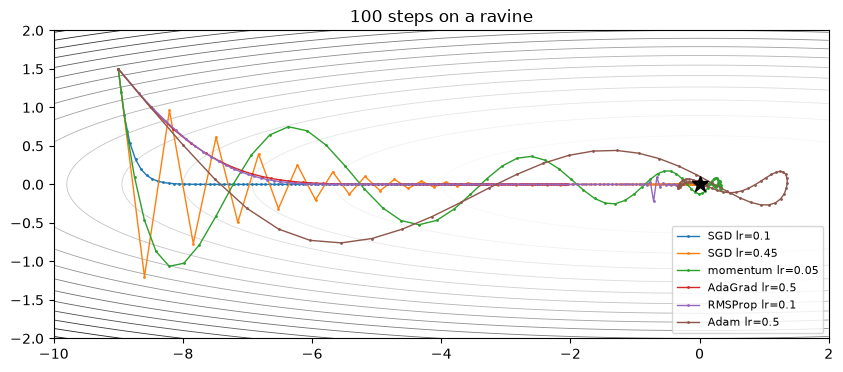

In [2]:
CURVATURE = np.array([0.1, 4.0])
loss_2d = lambda p: 0.5 * (CURVATURE * p ** 2).sum()
grad_2d = lambda p: CURVATURE * p


def sgd(lr):
    return lambda p, g, s, t: p - lr * g


def momentum(lr, mu=0.9):
    def step(p, g, s, t):
        s["v"] = mu * s.get("v", 0) + g
        return p - lr * s["v"]
    return step


def adagrad(lr):
    def step(p, g, s, t):
        s["G"] = s.get("G", 0) + g ** 2
        return p - lr * g / (np.sqrt(s["G"]) + 1e-8)
    return step


def rmsprop(lr, beta=0.9):
    def step(p, g, s, t):
        s["v"] = beta * s.get("v", 0) + (1 - beta) * g ** 2
        return p - lr * g / (np.sqrt(s["v"]) + 1e-8)
    return step


def adam(lr, b1=0.9, b2=0.999):
    def step(p, g, s, t):
        s["m"] = b1 * s.get("m", 0) + (1 - b1) * g
        s["v"] = b2 * s.get("v", 0) + (1 - b2) * g ** 2
        m_hat, v_hat = s["m"] / (1 - b1 ** t), s["v"] / (1 - b2 ** t)
        return p - lr * m_hat / (np.sqrt(v_hat) + 1e-8)
    return step


optimizers_2d = {"SGD lr=0.1": sgd(0.1), "SGD lr=0.45": sgd(0.45), "momentum lr=0.05": momentum(0.05),
                 "AdaGrad lr=0.5": adagrad(0.5), "RMSProp lr=0.1": rmsprop(0.1), "Adam lr=0.5": adam(0.5)}
paths = {}
for name, update in optimizers_2d.items():
    p, state, path = np.array([-9.0, 1.5]), {}, []
    for t in range(1, 101):
        path.append(p)
        p = update(p, grad_2d(p), state, t)
    paths[name] = np.array(path + [p])
    print(f"{name:<17} after 100 steps: point ({p[0]:6.3f}, {p[1]:6.3f}), loss {loss_2d(p):.5f}")

xs, ys = np.meshgrid(np.linspace(-10, 2, 200), np.linspace(-2, 2, 200))
plt.figure(figsize=(10, 4))
plt.contour(xs, ys, 0.5 * (0.1 * xs ** 2 + 4 * ys ** 2), levels=20, cmap="Greys", linewidths=0.6)
for name, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], ".-", markersize=2, linewidth=1, label=name)
plt.plot(0, 0, "k*", markersize=12)
plt.legend(fontsize=8, loc="lower right")
plt.title("100 steps on a ravine")
plt.show()

- **SGD, lr 0.1:** gets nowhere along the flat x direction (still at x = −3.3). Raising the learning rate to 0.45 helps (x = −0.09), but 0.5 is the limit: above it, the steep y direction would blow up. One learning rate can't suit both directions.
- **Momentum:** builds up speed along x and reaches the minimum (loss 0.00009) with a much smaller learning rate.
- **AdaGrad:** stalls at x = −2.0, because its steps keep shrinking.
- **RMSProp and Adam:** scale each direction separately, so both move at a similar pace. Adam ends as close as momentum.

# 5. ADAMW: WEIGHT DECAY DONE RIGHT

**Weight decay** shrinks every weight a little each step, which keeps weights small and reduces overfitting (03.2).
The classic way to do it is **L2 regularization**: add `λ · w` to the gradient. For plain SGD the two are the same thing.

With Adam they are not. Adam divides the whole gradient, including the `λ · w` term, by `√v`. Weights with large gradients get a large `√v`,
so their decay is divided away; weights with tiny gradients are decayed far too hard. **AdamW** (Loshchilov and Hutter) keeps the decay out of Adam's scaling
and applies it directly: `w ← w − lr · λ · w`, the same for every weight. AdamW is the standard optimizer for transformers and LLMs.

In PyTorch, `torch.optim.Adam(weight_decay=...)` is the L2 version and `torch.optim.AdamW(weight_decay=...)` is the decoupled one.
Below, two weights both start at 1.0. Their gradients average zero, so only the decay moves them, but one has large gradients (±10) and the other tiny ones (±0.01).

In [3]:
for optimizer_class in [torch.optim.Adam, torch.optim.AdamW]:
    w = nn.Parameter(torch.tensor([1.0, 1.0]))
    optimizer = optimizer_class([w], lr=0.01, weight_decay=0.1)
    for t in range(1000):
        sign = 1 if t % 2 == 0 else -1
        w.grad = torch.tensor([10.0 * sign, 0.01 * sign])        # mean-zero gradients, very different sizes
        optimizer.step()
    print(f"{optimizer_class.__name__:<6} (weight_decay=0.1): weight with large gradients {w[0].item():.4f}, weight with tiny gradients {w[1].item():.4f}")

Adam   (weight_decay=0.1): weight with large gradients 0.8890, weight with tiny gradients 0.0001
AdamW  (weight_decay=0.1): weight with large gradients 0.3614, weight with tiny gradients 0.3614


With Adam's L2-style decay, the weight with large gradients barely shrinks (0.889) while the one with tiny gradients is wiped out (0.0001): the decay depends on gradient size, which is not what weight decay is meant to do. AdamW shrinks both to exactly the same value (0.361 = 0.999¹⁰⁰⁰ plus tiny Adam steps).

# 6. OPTIMIZERS ON A REAL MODEL

The same MLP on FashionMNIST for 5 epochs with each optimizer, each at a learning rate that suits it.

In [4]:
candidates = {
    "SGD (lr 0.1)": lambda p: torch.optim.SGD(p, lr=0.1),
    "SGD + momentum (lr 0.05)": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "Nesterov (lr 0.05)": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, nesterov=True),
    "AdaGrad (lr 0.01)": lambda p: torch.optim.Adagrad(p, lr=0.01),
    "RMSProp (lr 1e-3)": lambda p: torch.optim.RMSprop(p, lr=1e-3),
    "Adam (lr 1e-3)": lambda p: torch.optim.Adam(p, lr=1e-3),
    "AdamW (lr 1e-3, wd 0.01)": lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=0.01),
}
for name, make in candidates.items():
    acc = train(make)
    print(f"{name:<26} validation accuracy  after epoch 1: {acc[0]:.4f}   after epoch 5: {acc[-1]:.4f}")

SGD (lr 0.1)               validation accuracy  after epoch 1: 0.8402   after epoch 5: 0.8828


SGD + momentum (lr 0.05)   validation accuracy  after epoch 1: 0.8470   after epoch 5: 0.8838


Nesterov (lr 0.05)         validation accuracy  after epoch 1: 0.8595   after epoch 5: 0.8853


AdaGrad (lr 0.01)          validation accuracy  after epoch 1: 0.8573   after epoch 5: 0.8853


RMSProp (lr 1e-3)          validation accuracy  after epoch 1: 0.8530   after epoch 5: 0.8800


Adam (lr 1e-3)             validation accuracy  after epoch 1: 0.8585   after epoch 5: 0.8793


AdamW (lr 1e-3, wd 0.01)   validation accuracy  after epoch 1: 0.8593   after epoch 5: 0.8800


With a suitable learning rate, every optimizer ends within 0.6% of the others after 5 epochs (0.879 to 0.885) on this easy problem. They differ more early on: plain SGD is the slowest after the first epoch (0.840) and Nesterov the fastest (0.860).

The bigger practical difference is **how sensitive** each optimizer is to the learning rate. Two epochs at five learning rates:

In [5]:
lrs = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
for name, make in {"SGD + momentum": lambda lr: (lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9)),
                   "Adam": lambda lr: (lambda p: torch.optim.Adam(p, lr=lr))}.items():
    results = [train(make(lr), epochs=2)[-1] for lr in lrs]
    print(f"{name:<15}" + "".join(f"  lr {lr:g}: {acc:.3f}" for lr, acc in zip(lrs, results)))

SGD + momentum   lr 0.0001: 0.582  lr 0.001: 0.799  lr 0.01: 0.855  lr 0.1: 0.836  lr 1: 0.105


Adam             lr 0.0001: 0.843  lr 0.001: 0.867  lr 0.01: 0.857  lr 0.1: 0.105  lr 1: 0.104


Adam stays between 0.843 and 0.867 across a 100x range of learning rates (1e-4 to 1e-2). SGD with momentum swings from 0.582 to 0.855 over the same range. Both diverge (0.10, chance level) when the learning rate is far too high. Adam's robustness is a big reason it is the default: one wrong guess costs much less.

# 7. OPTIMIZER MEMORY

Optimizers store extra numbers for every weight: momentum keeps one (the velocity), Adam keeps two (`m` and `v`).
For large models this memory is as important as the weights themselves.

In [6]:
model = make_mlp()
n_params = sum(p.numel() for p in model.parameters())
for name, optimizer in {"SGD": torch.optim.SGD(model.parameters(), lr=0.01),
                        "SGD + momentum": torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9),
                        "Adam": torch.optim.Adam(model.parameters())}.items():
    model.zero_grad()
    nn.functional.cross_entropy(model(X_train[:BATCH]), y_train[:BATCH]).backward()
    optimizer.step()                                     # optimizer state is created on the first step
    stored = sum(t.numel() for s in optimizer.state.values() for t in s.values() if torch.is_tensor(t) and t.numel() > 1)
    print(f"{name:<15} {n_params:,} parameters, {stored:,} extra numbers stored ({stored / n_params:.0f}x)")

SGD             235,146 parameters, 0 extra numbers stored (0x)
SGD + momentum  235,146 parameters, 235,146 extra numbers stored (1x)
Adam            235,146 parameters, 470,292 extra numbers stored (2x)


Adam stores 470,292 numbers for 235,146 parameters: two per weight. For a 7B-parameter model, Adam's two float32 states alone take 56 GB, on top of the weights and gradients.
This is why large-model training shards the optimizer state across GPUs (ZeRO and FSDP, 03.3), and why 8-bit optimizers and LoRA (folder 13) exist.

# 8. LEARNING-RATE SCHEDULES

A large learning rate makes fast progress early; a small one settles into a good minimum at the end. A **schedule** changes the learning rate during training.

| Schedule | Shape | PyTorch |
|---|---|---|
| constant | flat | no scheduler |
| step decay | drop by 10x at set epochs | `StepLR`, `MultiStepLR` |
| exponential | multiply by γ every step | `ExponentialLR` |
| cosine | smooth curve from the peak to near zero | `CosineAnnealingLR` |
| warm-up + cosine | rise linearly, then cosine down (the LLM standard) | `LambdaLR`, or `LinearLR` + `CosineAnnealingLR` in `SequentialLR` |
| one-cycle | rise to a high peak, then fall well below the start | `OneCycleLR` |
| reduce on plateau | drop when the validation metric stops improving | `ReduceLROnPlateau` (stepped with the metric) |

Call `scheduler.step()` after `optimizer.step()`, either once per batch or once per epoch, consistently with how the schedule was defined.

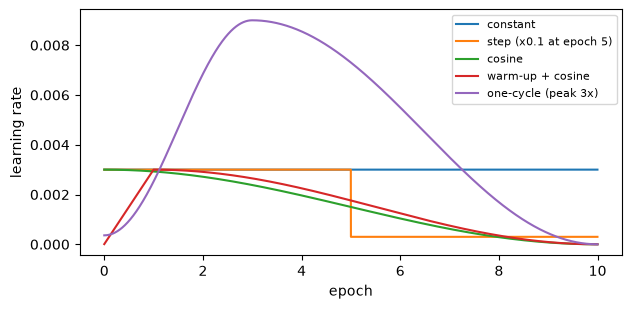

In [7]:
EPOCHS = 10
TOTAL = EPOCHS * STEPS_PER_EPOCH
WARMUP = STEPS_PER_EPOCH                                   # one epoch of warm-up


def warmup_cosine(optimizer):
    def factor(step):                                      # multiplier on the base learning rate
        if step < WARMUP:
            return (step + 1) / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (step - WARMUP) / (TOTAL - WARMUP)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)


schedules = {
    "constant": None,
    "step (x0.1 at epoch 5)": lambda o: torch.optim.lr_scheduler.StepLR(o, step_size=5 * STEPS_PER_EPOCH, gamma=0.1),
    "cosine": lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=TOTAL),
    "warm-up + cosine": warmup_cosine,
    "one-cycle (peak 3x)": lambda o: torch.optim.lr_scheduler.OneCycleLR(o, max_lr=9e-3, total_steps=TOTAL),
}

plt.figure(figsize=(7, 3.2))
for name, make in schedules.items():
    optimizer = torch.optim.Adam([nn.Parameter(torch.zeros(1))], lr=3e-3)
    scheduler = make(optimizer) if make else None
    lr_curve = []
    for _ in range(TOTAL):
        lr_curve.append(optimizer.param_groups[0]["lr"])
        optimizer.step()
        if scheduler:
            scheduler.step()
    plt.plot(np.arange(TOTAL) / STEPS_PER_EPOCH, lr_curve, label=name)
plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.legend(fontsize=8)
plt.show()

Now the same five schedules training the MLP for 10 epochs with Adam at a base learning rate of 3e-3:

constant                 validation accuracy  epoch 5: 0.8817   epoch 10: 0.8875   best: 0.8875


step (x0.1 at epoch 5)   validation accuracy  epoch 5: 0.8817   epoch 10: 0.8952   best: 0.8952


cosine                   validation accuracy  epoch 5: 0.8815   epoch 10: 0.8990   best: 0.8990


warm-up + cosine         validation accuracy  epoch 5: 0.8870   epoch 10: 0.8988   best: 0.8988


one-cycle (peak 3x)      validation accuracy  epoch 5: 0.8748   epoch 10: 0.8898   best: 0.8905


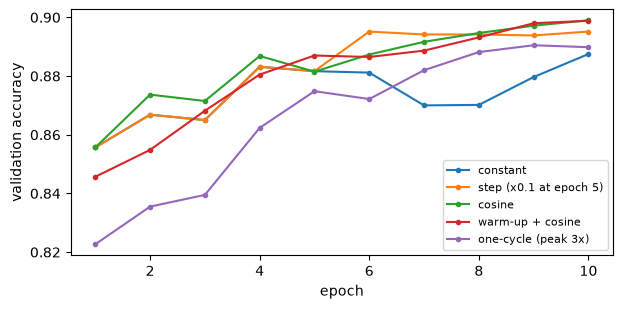

In [8]:
schedule_results = {}
for name, make in schedules.items():
    acc = train(lambda p: torch.optim.Adam(p, lr=3e-3), epochs=EPOCHS, make_scheduler=make)
    schedule_results[name] = acc
    print(f"{name:<24} validation accuracy  epoch 5: {acc[4]:.4f}   epoch 10: {acc[-1]:.4f}   best: {max(acc):.4f}")

plt.figure(figsize=(7, 3.2))
for name, acc in schedule_results.items():
    plt.plot(range(1, EPOCHS + 1), acc, marker=".", label=name)
plt.xlabel("epoch")
plt.ylabel("validation accuracy")
plt.legend(fontsize=8)
plt.show()

Every decaying schedule beats the constant learning rate (0.888): step decay reaches 0.895, cosine 0.899, and warm-up + cosine 0.899. The step schedule shows the effect clearly: accuracy jumps right after the drop at epoch 5. One-cycle with a peak of 9e-3 (3x the base) ends at 0.890: its peak is too high for this model, a reminder that schedules still need a sensible peak learning rate.

# 9. WARM-UP

**Warm-up** starts with a tiny learning rate and raises it linearly over the first few hundred or thousand steps. Why:
- At the start, the weights are random and Adam's `v` estimate is based on very few gradients, so the first updates can be huge and push training somewhere it never recovers from.
- Transformers are especially sensitive: without warm-up, large models often diverge (the loss goes to NaN) in the first steps.
- With very large batches, the learning rate is scaled up (section 11), and warm-up makes that safe.

On this small MLP, warm-up neither helps nor hurts: warm-up + cosine ends at 0.899, the same as cosine alone. Small models with normalized inputs rarely need it. Transformers do, which is why every LLM training recipe includes it.

Rule of thumb for transformers: warm up over roughly 1–5% of the total steps, then decay with cosine to about 10% of the peak.

# 10. FINDING A LEARNING RATE: THE RANGE TEST

The learning rate is the most important hyperparameter. A quick way to find a good range (Leslie Smith's **LR range test**):
start very low, multiply the learning rate a little after every batch, and record the loss. The loss falls, flattens, then explodes.
A good learning rate is about 10x smaller than the one where the loss was lowest.

lowest smoothed loss at lr 0.100; suggested learning rate about 0.010; stopped at lr 0.63


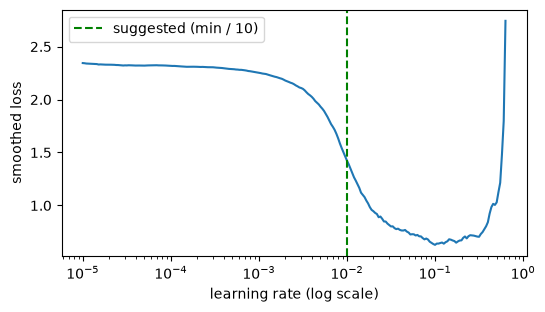

In [9]:
def lr_range_test(lr_min: float = 1e-5, lr_max: float = 10.0, steps: int = 300):
    torch.manual_seed(0)
    model = make_mlp()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr_min, momentum=0.9)
    growth = (lr_max / lr_min) ** (1 / steps)               # multiply the learning rate by this every step
    perm = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(0))
    lrs, losses, smooth = [], [], None
    for step in range(steps):
        lr = lr_min * growth ** step
        for group in optimizer.param_groups:
            group["lr"] = lr
        idx = perm[step * BATCH:(step + 1) * BATCH]
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(model(X_train[idx]), y_train[idx])
        loss.backward()
        optimizer.step()
        smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()     # the raw loss is noisy
        lrs.append(lr)
        losses.append(smooth)
        if smooth > 4 * min(losses):                         # the loss has exploded
            break
    return lrs, losses


lrs_tested, losses_tested = lr_range_test()
best_lr = lrs_tested[int(np.argmin(losses_tested))]
print(f"lowest smoothed loss at lr {best_lr:.3f}; suggested learning rate about {best_lr / 10:.3f}; stopped at lr {lrs_tested[-1]:.2f}")

plt.figure(figsize=(6, 3.2))
plt.semilogx(lrs_tested, losses_tested)
plt.axvline(best_lr / 10, color="green", linestyle="--", label="suggested (min / 10)")
plt.xlabel("learning rate (log scale)")
plt.ylabel("smoothed loss")
plt.legend()
plt.show()

The smoothed loss is lowest at a learning rate of about 0.1 and explodes past 0.6, so the suggestion is 0.01. That is exactly the learning rate that scored best for SGD with momentum in the section 6 grid (0.855), found in one pass of 300 batches instead of five full training runs.

# 11. BATCH SIZE, LEARNING RATE AND NEWER OPTIMIZERS

**Batch size and learning rate go together.** A bigger batch gives a less noisy gradient, so it can take bigger steps.
- **Linear scaling rule** (for SGD): multiply the batch size by k, multiply the learning rate by k, and add warm-up. It holds up to a point, then breaks down.
- For Adam, scaling the learning rate by about √k is a common starting point.
- Very large batches can generalize worse; LARS and LAMB adjust the step size per layer to train with huge batches.

**Optimizers you'll hear about:**

| Optimizer | Idea | Why people use it |
|---|---|---|
| Adafactor | stores row and column averages instead of a full `v` per weight | much less optimizer memory (used for T5) |
| 8-bit Adam (bitsandbytes) | keeps `m` and `v` in 8 bits | about 4x less optimizer memory, common for fine-tuning |
| Lion | only the sign of a momentum-like update | less memory than Adam, found by an automated search |
| Muon | orthogonalizes the momentum update for 2D weight matrices | faster training of transformer weights in recent LLM work; AdamW is still used for the other parameters |
| Shampoo / SOAP | approximate second-order (curvature) information | fewer steps, more compute per step |

AdamW remains the default for transformers; SGD with momentum is still common for CNNs, where it often generalizes slightly better.

# 12. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Optimizer | SGD + momentum / Adam / AdamW | SGD: least memory, often generalizes well, but needs careful learning-rate tuning and a schedule. Adam: works out of the box across learning rates, 2x extra memory. AdamW: Adam with correct weight decay | AdamW for transformers and most new work; SGD + momentum for CNNs when tuned |
| Weight decay with Adam | `Adam(weight_decay)` / `AdamW` | Adam's L2 version decays weights unevenly (section 5); AdamW decays them all the same | AdamW |
| Learning rate | low / high | low: stable but slow. High: fast, then noisy or divergent | range test, then a small search around it |
| Schedule | constant / step / cosine / warm-up + cosine / one-cycle | constant: simple but ends noisy. Step: needs the drop epochs chosen. Cosine: smooth, one setting fewer. Warm-up: protects the first steps | warm-up + cosine for transformers; cosine or one-cycle for CNNs |
| Schedule unit | per epoch / per step | per epoch: simple. Per step: smooth, and works for runs measured in steps (LLMs) | per step |
| Optimizer memory | Adam / 8-bit Adam / Adafactor | Adam: best tested. 8-bit and Adafactor: much less memory, small risk to quality | Adam unless memory is the limit |
| Batch size | small / large | small: noisy, may generalize better, poor GPU use. Large: fast, needs a scaled learning rate with warm-up | the largest that fits, with the learning rate scaled to match |

# 13. INTERVIEW QUESTIONS

### Q1. Explain Adam, in 30 seconds.
Adam keeps two running averages per weight: the gradient (momentum, β1 = 0.9) and the squared gradient (β2 = 0.999). It corrects both for starting at zero,
then updates each weight by `lr · m̂ / (√v̂ + ε)`. The momentum smooths the direction; dividing by `√v̂` gives each weight its own step size,
so every weight moves by roughly `lr` regardless of its gradient scale. It costs two extra numbers per weight.

### Q2. Why does momentum help?
It averages gradients over recent steps. Directions that stay consistent build up speed, while zig-zags across a ravine cancel out,
so it is faster on badly scaled losses and carries the weights across flat regions and saddle points.

### Q3. SGD or Adam: when would you use each?
Adam (or AdamW) converges fast with little tuning and is the default for transformers. SGD with momentum uses less memory and,
well tuned with a schedule, often generalizes slightly better on vision tasks. Adam is much less sensitive to the learning rate (section 6).

### Q4. What is bias correction in Adam?
`m` and `v` start at zero, so for the first steps they are biased towards zero. Dividing by `1 − β1^t` and `1 − β2^t` removes that bias; the effect fades as t grows.

### Q5. What's the difference between Adam with weight decay and AdamW?
Adam's `weight_decay` adds `λw` to the gradient (L2), which then gets divided by `√v`, so weights with large gradients are barely decayed.
AdamW applies the decay directly to the weights, separately from the adaptive step, so every weight decays at the same rate. AdamW is the standard for transformers.

### Q6. Why use a learning-rate schedule?
A high learning rate makes fast progress early, but bounces around the minimum; lowering it later lets the model settle into a better point.
In section 8, decaying schedules ended about 1% more accurate than a constant learning rate.

### Q7. Why do transformers need warm-up?
At the start the weights are random and Adam's variance estimate is based on very few gradients, so full-size updates can be destructive
and training can diverge. Warm-up raises the learning rate gradually over the first steps. It also makes large-batch training with a scaled learning rate stable.

### Q8. How do you choose a learning rate?
Start from known defaults (1e-3 for Adam; around 3e-4 for transformers), run an LR range test, and search a few values on a log scale around it.
Tune the learning rate before anything else, and re-tune it when the batch size changes.

### Q9. How are batch size and learning rate related?
Larger batches give less noisy gradients, so they can take larger steps. The linear scaling rule multiplies the learning rate by k when the batch grows by k (for SGD, with warm-up);
for Adam, √k is a common start. Past some batch size, returns diminish.

### Q10. How much memory does the optimizer use?
SGD: none extra. Momentum: one number per weight. Adam/AdamW: two per weight, so for a 7B model 56 GB in float32 just for the optimizer state.
Fixes include sharding the state across GPUs (ZeRO, FSDP), 8-bit optimizers, Adafactor, and training only a few weights (LoRA).

### Q11. Why does AdaGrad stop learning?
It divides by the square root of the *sum* of all past squared gradients. That sum only grows, so the effective learning rate shrinks towards zero. RMSProp and Adam use a running average instead.

### Q12. Are local minima a big problem in deep learning?
Less than expected. In high dimensions, most points with zero gradient are saddle points rather than bad minima, and most minima found by SGD-type methods have similar loss.
Plateaus and saddle points slow training, and momentum and adaptive methods help get through them.

### Q13. The loss suddenly becomes NaN. What do you check on the optimizer side?
A learning rate that is too high, a missing warm-up, exploding gradients (add gradient clipping, 03.3), float16 overflow (03.3), or ε being too small.
Lower the learning rate first; log the gradient norm to see where it blows up.

# 14. IN MY OWN WORDS

Write this from memory, without looking above:

- What momentum does, and why it helps in a ravine:
- Adam's update, in words:
- Why AdamW instead of Adam with weight decay:
- Why schedules and warm-up help:
- How I would pick a learning rate for a new model: